# GraphCast vs AIFS: 2025 Tennessee Valley Flood (ERA5-initialized)

A controlled comparison of two AI weather models on the April 2025 Tennessee Valley flood, when days of repeated heavy rain flooded the Ohio and Tennessee valleys. Google DeepMind's GraphCast Operational and ECMWF's AIFS are both run through NVIDIA Earth2Studio from the same ERA5/ARCO state (ERA5 from Google's ARCO archive, the `ARCO_ERA5` data source) at 2025-04-01 00Z, for 20 six-hourly steps (to 2025-04-06 00Z). Because the initial condition is shared, the model is the only difference (the WeatherBench 2 same-analysis convention). The two forecasts are compared on daily precipitation maps, at cities, and against ERA5 daily precipitation over the Tennessee Valley box (33–40.5°N, 95–82°W). "AIFS" here is AIFS v1 (AIFS Single; Earth2Studio 0.20.0 loads its `aifs-single-1.1` checkpoint), not the newer AIFS 2.

> **Measured on an NVIDIA L40:** 7 min runtime · 39.5 GiB peak GPU memory.

1. Setup
2. Configuration
3. Run GraphCast
4. Run AIFS v1
5. Daily precipitation and map helpers
6. Verify against ERA5
7. Daily maps
8. Side-by-side comparison — maps, city table, domain max
9. Nashville time series

## 1 · Setup

Both models read their initial state from ERA5 on ARCO (no credentials needed); the ERA5 precipitation used for scoring in section 6 comes from the Copernicus Climate Data Store and needs `~/.cdsapirc`. The `aifs` and `graphcast` extras of earth2studio, installed by `uv sync`, bring the AIFS v1 stack (`anemoi-models` 0.5.1) and GraphCast's JAX stack, so no extra `pip install` is needed.

GraphCast runs in JAX and AIFS in PyTorch inside the same kernel. `XLA_PYTHON_CLIENT_PREALLOCATE=false` stops JAX from reserving most of the GPU up front, `XLA_PYTHON_CLIENT_ALLOCATOR=platform` makes JAX return freed memory to the driver (by default it keeps everything it has used until the kernel exits, which would leave AIFS only a few GiB), and `free_gpu(...)` releases each model after its run. A forecast cell that fails deletes its half-written Zarr store, because the reuse check in sections 3 and 4 would otherwise read a partial forecast back. If a forecast run is interrupted or fails part-way (for example AIFS running out of GPU memory after GraphCast), delete that run's `.zarr` folder if it is still there (`aifs_tn_flood_outputs/aifs_tn_ic0401.zarr` for AIFS, `tn_model_compare_outputs/graphcast_tn_era5_ic0401.zarr` for GraphCast), then restart the kernel and run all cells again. A completed forecast is read back instead of re-run, so after the restart AIFS has the GPU to itself.

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # jax (GraphCast) + torch (AIFS) share GPU
os.environ.setdefault("XLA_PYTHON_CLIENT_ALLOCATOR", "platform")  # and JAX returns freed memory to the driver, so AIFS can use it after GraphCast

import gc
import shutil
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import torch
import xarray as xr

import earth2studio.run as run
from earth2studio.data import ARCO_ERA5
from earth2studio.io import ZarrBackend
from earth2studio.models.px import AIFS, GraphCastOperational

from era5_truth import compute_daily_total_precip

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)


class _ZarrIO:
    """Minimal io-like wrapper so the compute/plot helpers work on an opened Zarr store."""

    def __init__(self, ds):
        self.ds = ds

    def __getitem__(self, key):
        return self.ds[key].values

Device: cuda


## 2 · Configuration

Every value a reader may want to change lives here: the shared initial time, the days compared, the region, the cities, and where the two forecasts are stored.

In [2]:
# Event and shared forecast setup
EVENT_NAME = "2025 Tennessee Valley Flood"
FORECAST_INIT = "2025-04-01T00:00:00"
NSTEPS = 20  # 20 x 6h = Apr 1 00Z -> Apr 6 00Z (covers the April 5 daily total)

# Days compared: ERA5 scores and the Nashville series use COMPARE_DATES; maps and the city table use COMPARE_DATES_2M
COMPARE_DATES = ["2025-04-02", "2025-04-03", "2025-04-04", "2025-04-05"]
COMPARE_DATES_2M = ["2025-04-04", "2025-04-05"]

# Tennessee Valley region [lon_min, lon_max, lat_min, lat_max]; also the ERA5 scoring box (era5_truth.TN_BOX)
EXTENT = [-95, -82, 33, 40.5]

# Point for the time series (longitude in 0-360)
POI_LAT = 36.16
POI_LON = 360 - 86.78
POI_LABEL = "Nashville, TN"

# Cities marked on the maps and listed in the city table; Nashville is also the point used for the time series in section 9
CITIES = [
    {"lat": 39.78, "lon": 360 - 89.65, "label": "Springfield, IL"},
    {"lat": 39.77, "lon": 360 - 86.16, "label": "Indianapolis, IN"},
    {"lat": 39.10, "lon": 360 - 84.51, "label": "Cincinnati, OH"},
    {"lat": 38.63, "lon": 360 - 90.20, "label": "St Louis, MO"},
    {"lat": 38.25, "lon": 360 - 85.76, "label": "Louisville, KY"},
    {"lat": 36.37, "lon": 360 - 94.21, "label": "Bentonville, AR"},
    {"lat": POI_LAT, "lon": POI_LON, "label": POI_LABEL},
    {"lat": 35.15, "lon": 360 - 90.05, "label": "Memphis, TN"},
]

# Outputs (paths relative to the notebook folder). A forecast whose Zarr store exists is read back, not re-run.
PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUTPUT_DIR = "tn_model_compare_outputs"
GRAPHCAST_ZARR = f"{OUTPUT_DIR}/graphcast_tn_era5_ic0401.zarr"
AIFS_ZARR = "aifs_tn_flood_outputs/aifs_tn_ic0401.zarr"  # kept in its own folder
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 3 · Run GraphCast

If GraphCast's Zarr store already exists, the forecast is read back instead of re-run (rename or delete the folder to force a new run). Otherwise the model is loaded, run from the ERA5 state with only `tp06` (6-hour precipitation) kept, and released; if the run fails, its partial store is deleted so that it is never reused.

In [3]:
if os.path.exists(GRAPHCAST_ZARR):
    print("Reusing existing GraphCast forecast:", GRAPHCAST_ZARR)
    gc_io = _ZarrIO(xr.open_zarr(GRAPHCAST_ZARR, consolidated=False))
else:
    try:
        gc_package = GraphCastOperational.load_default_package()
        gc_model = GraphCastOperational.load_model(gc_package)
        gc_store = ZarrBackend(GRAPHCAST_ZARR, backend_kwargs={"overwrite": True})
        gc_io = run.deterministic(
            [FORECAST_INIT], NSTEPS, gc_model, ARCO_ERA5(), gc_store,
            output_coords={"variable": np.array(["tp06"])},
        )
    except BaseException:
        shutil.rmtree(GRAPHCAST_ZARR, ignore_errors=True)  # the reuse check above must never read a partial store
        raise
    finally:
        free_gpu("gc_model", "gc_package")

print("GraphCast tp06 shape:", gc_io["tp06"].shape)

2026-11-01 02:51:19.061 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 02:51:19.061 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 02:51:22.873 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from ARCO_ERA5
2026-11-01 02:51:22.874 | INFO     | earth2studio.run:deterministic:162 - Inference starting!


E1101 02:53:24.756345   18427 slow_operation_alarm.cc:74] 
********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************
E1101 02:55:13.289916   18415 slow_operation_alarm.cc:141] The operation took 3m48.533716734s

********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


2026-11-01 02:56:42.761 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete
GraphCast tp06 shape: (1, 21, 721, 1440)


## 4 · Run AIFS v1

The same pattern for AIFS: it runs whenever its Zarr store is missing, from the same ERA5 state and for the same 20 steps.

In [4]:
if os.path.exists(AIFS_ZARR):
    print("Reusing existing AIFS forecast:", AIFS_ZARR)
    aifs_io = _ZarrIO(xr.open_zarr(AIFS_ZARR, consolidated=False))
else:
    try:
        aifs_package = AIFS.load_default_package()
        aifs_model = AIFS.load_model(aifs_package)
        aifs_store = ZarrBackend(AIFS_ZARR, backend_kwargs={"overwrite": True})
        aifs_io = run.deterministic(
            [FORECAST_INIT], NSTEPS, aifs_model, ARCO_ERA5(), aifs_store,
            output_coords={"variable": np.array(["tp06"])},
        )
    except BaseException:
        shutil.rmtree(AIFS_ZARR, ignore_errors=True)  # the reuse check above must never read a partial store
        raise
    finally:
        free_gpu("aifs_model", "aifs_package")

print("AIFS tp06 shape:", aifs_io["tp06"].shape)

2026-11-01 02:56:49.892 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 02:56:49.893 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 02:56:53.811 | SUCCESS  | earth2studio.run:deterministic:154 - Fetched data from ARCO_ERA5
2026-11-01 02:56:53.813 | INFO     | earth2studio.run:deterministic:162 - Inference starting!
2026-11-01 02:57:09.099 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete
AIFS tp06 shape: (1, 21, 721, 1440)


## 5 · Daily precipitation and map helpers

For both models each `tp06` value is the rain (in metres) that fell in the 6 hours ending at that step's valid time; step 0 is the initial state and is all zeros. A UTC day D is the sum of the four steps valid at D 06Z, 12Z, 18Z and D+1 00Z, which is the window (D 00Z, D+1 00Z]. The ERA5 daily totals in section 6 use the same window. Both `compute_daily_total_precip` and the ERA5 daily totals live in `era5_truth.py`, whose unit tests check that the two use the same day.

In [5]:
PRECIP_LEVELS = [1, 5, 10, 20, 30, 50, 75, 100, 150]
PRECIP_CMAP = plt.cm.rainbow_r  # red = light rain, blue-purple = heavy rain
PRECIP_NORM = mcolors.BoundaryNorm(PRECIP_LEVELS, PRECIP_CMAP.N, extend="max")


def _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=None):
    """Draw one daily-precip field onto a cartopy axes; return the contourf mappable."""
    # extend="max" colours totals above the top level instead of leaving them blank
    im = ax.contourf(
        lon, lat, precip,
        levels=PRECIP_LEVELS, cmap=PRECIP_CMAP, norm=PRECIP_NORM,
        transform=ccrs.PlateCarree(), extend="max",
    )
    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.coastlines(linewidth=0.8)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax.set_extent(extent)

    for city in poi or []:
        ax.plot(
            city["lon"] - 360, city["lat"],
            marker="*", color="lime", markersize=7,
            markeredgecolor="black", markeredgewidth=0.5,
            transform=ccrs.PlateCarree(), zorder=5,
        )
        ax.text(
            city["lon"] - 360 + 0.15, city["lat"] + 0.15, city["label"],
            fontsize=7, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="gray", alpha=0.8),
            transform=ccrs.PlateCarree(), zorder=5,
        )
    ax.set_title(label, fontsize=11)
    return im


def plot_single_panel(precip, label, lon, lat, extent, poi=None, save_path=None):
    """One daily-precip map in the tall house layout."""
    plt.close("all")

    fig, ax = plt.subplots(
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 8),
    )
    im = _draw_precip_axes(ax, precip, label, lon, lat, extent, poi=poi)
    cbar = map_colorbar(fig, ax, im, label="Total Precipitation (mm)", orientation="horizontal")
    cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()


def domain_max_location(field, lon, lat, extent):
    """Max precip within the plotted extent and its (lat, lon), lon in -180..180 degrees."""
    lon_min, lon_max = extent[0] + 360, extent[1] + 360   # -95, -82 -> 265, 278
    lat_min, lat_max = extent[2], extent[3]
    lat_sel = (lat >= lat_min) & (lat <= lat_max)
    lon_sel = (lon >= lon_min) & (lon <= lon_max)
    sub = field[np.ix_(lat_sel, lon_sel)]
    i, j = np.unravel_index(np.argmax(sub), sub.shape)
    return float(sub[i, j]), float(lat[lat_sel][i]), float(lon[lon_sel][j] - 360)


def plot_model_comparison(precip_gc, precip_ai, date, lon, lat, extent, poi, save_path=None):
    """GraphCast (top) vs AIFS (bottom) on the same rainbow_r scale and levels (tall layout)."""
    plt.close("all")

    fig, axes = plt.subplots(
        2, 1, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(6, 9.8),  # room for each bar label
    )
    for ax, precip, name in zip(axes, [precip_gc, precip_ai], ["GraphCast", "AIFS v1"]):
        im = _draw_precip_axes(ax, precip, f"{name} | {date}", lon, lat, extent, poi=poi)
        cbar = map_colorbar(fig, ax, im, label="Total Precipitation (mm)", orientation="horizontal")
        cbar.ax.tick_params(labelsize=8)

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

## 6 · Verify against ERA5

Which model is closer to an independent estimate of the rain that fell? Each model's daily totals for April 2–5 are compared with ERA5 daily totals for the same UTC windows (section 5) over the Tennessee Valley box (33–40.5°N, 95–82°W, `era5_truth.TN_BOX`) on the model grid. Hourly ERA5 precipitation comes from the Copernicus Climate Data Store (it needs `~/.cdsapirc` credentials) and is cached in `OUTPUT_DIR`; the same daily fields fill the ERA5 column of the city table in section 8.

> **Truth caveat:** ERA5 precipitation is itself model-derived (it is a reanalysis product), so these scores measure agreement with ERA5, not with rain gauges or radar. Both forecasts also start from ERA5, so neither model has an advantage from the reference.

**How to read the tables.** The first table has one row per model and day; the second averages April 2–5 for each model. Bias = forecast − ERA5 in mm/day (positive means too wet), averaged over the box with area weights; RMSE and MAE are the typical size of the point-by-point error in mm/day; Pattern corr = spatial correlation of the daily rainfall pattern (1 means the rain is in the right places, whatever the amounts). Both models have the same lead times, so differences between the rows come from the models.

In [6]:
from era5_truth import TN_ERA5_AREA, fetch_era5_daily_precip, forecast_vs_era5
from metrics import skill_row

era5_daily = fetch_era5_daily_precip(COMPARE_DATES, TN_ERA5_AREA, f"{OUTPUT_DIR}/era5_tp_tn.nc")

rows = []
for date in COMPARE_DATES:
    for model, run_store in (("GraphCast", gc_io), ("AIFS", aifs_io)):
        fc, ref, lats = forecast_vs_era5(
            compute_daily_total_precip(run_store, date, FORECAST_INIT),
            era5_daily.sel(day=np.datetime64(date)), run_store["lat"][:], run_store["lon"][:],
        )
        rows.append({"Model": model, "Date": date, **skill_row(fc, ref, lats)})

daily_skill = pd.DataFrame(rows)
nan_days = daily_skill.loc[daily_skill.isna().any(axis=1), "Date"].unique()
if len(nan_days):  # an incomplete ERA5 or forecast day must not be averaged away silently
    raise ValueError(f"NaN skill score on {', '.join(nan_days)}: incomplete ERA5 or forecast data for that day")
metrics_df = (
    daily_skill.groupby("Model")[["Bias", "RMSE", "MAE", "Pattern corr"]].mean().round(3).reset_index()
)
daily_skill.to_csv(RESULTS_DIR / "tennessee_valley_flood_model_comparison_daily.csv", index=False)
metrics_df.to_csv(RESULTS_DIR / "tennessee_valley_flood_model_comparison_metrics.csv", index=False)
print("Daily skill vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)\n")
print(daily_skill.to_string(index=False))
print("\nMean over Apr 2-5\n")
print(metrics_df.to_string(index=False))

2026-11-01 02:57:12,681 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-01 02:57:13,400 INFO Request ID is 735cc2a2-7d69-4224-bfc7-40678b5975b8
INFO:ecmwf.datastores.legacy_client:Request ID is 735cc2a2-7d69-4224-bfc7-40678b5975b8
2026-11-01 02:57:13,596 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successf

Daily skill vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)

    Model       Date   Bias   RMSE    MAE  Pattern corr
GraphCast 2025-04-02  0.405  8.144  5.196         0.746
     AIFS 2025-04-02  0.736  8.154  5.378         0.748
GraphCast 2025-04-03  1.504 11.373  6.053         0.914
     AIFS 2025-04-03  1.818 13.560  8.625         0.865
GraphCast 2025-04-04  3.539 15.258 10.319         0.671
     AIFS 2025-04-04  2.269 14.881 10.629         0.642
GraphCast 2025-04-05 -0.531 19.863 12.586         0.810
     AIFS 2025-04-05 -1.510 19.232 11.945         0.822

Mean over Apr 2-5

    Model  Bias   RMSE   MAE  Pattern corr
     AIFS 0.828 13.957 9.144         0.769
GraphCast 1.229 13.660 8.538         0.785


## 7 · Daily maps

Each model's daily totals for the last two forecast days, when the flood-producing rain was falling, on identical maps.

### GraphCast daily maps


Saved: tn_model_compare_outputs/graphcast_daily_2025-04-04.png


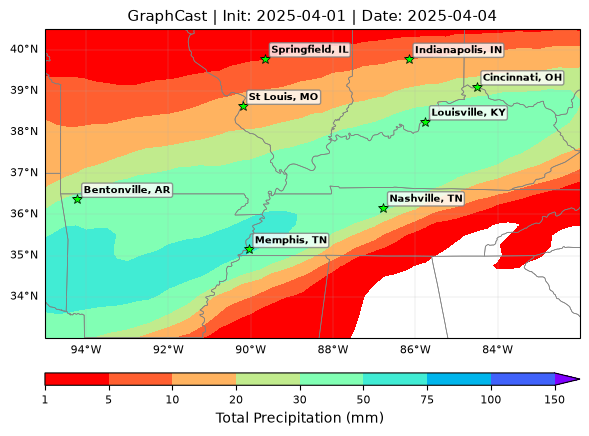

Saved: tn_model_compare_outputs/graphcast_daily_2025-04-05.png


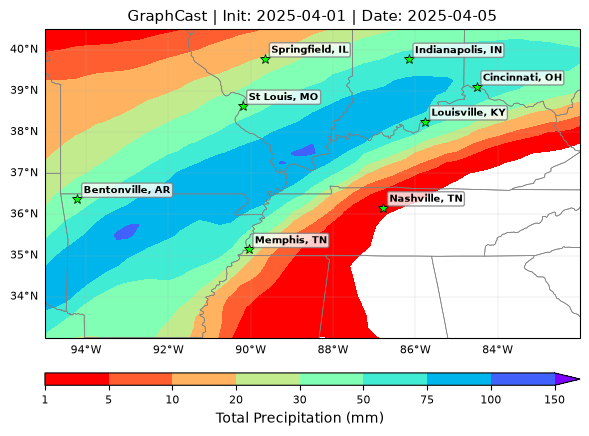

In [7]:
for date in COMPARE_DATES_2M:
    precip = compute_daily_total_precip(gc_io, date, FORECAST_INIT)
    plot_single_panel(
        precip,
        f"GraphCast | Init: {FORECAST_INIT[:10]} | Date: {date}",
        gc_io["lon"][:], gc_io["lat"][:], EXTENT, poi=CITIES,
        save_path=f"{OUTPUT_DIR}/graphcast_daily_{date}.png",
    )

### AIFS daily maps


Saved: tn_model_compare_outputs/aifs_daily_2025-04-04.png


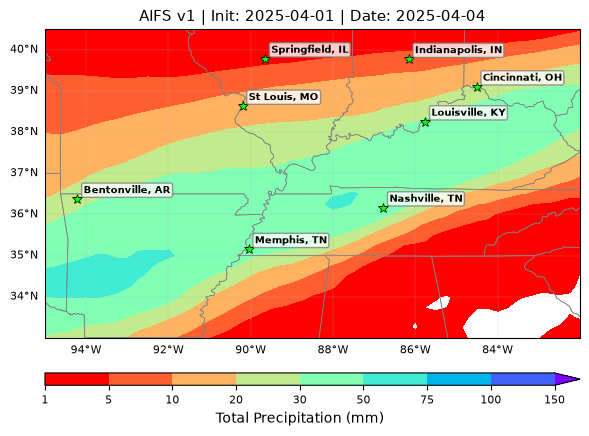

Saved: tn_model_compare_outputs/aifs_daily_2025-04-05.png


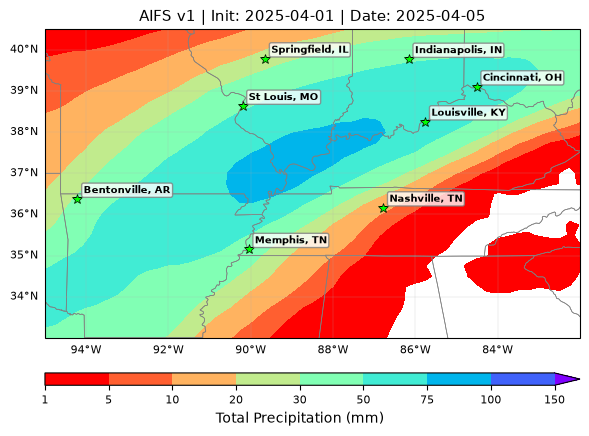

In [8]:
for date in COMPARE_DATES_2M:
    precip = compute_daily_total_precip(aifs_io, date, FORECAST_INIT)
    plot_single_panel(
        precip,
        f"AIFS v1 | Init: {FORECAST_INIT[:10]} | Date: {date}",
        aifs_io["lon"][:], aifs_io["lat"][:], EXTENT, poi=CITIES,
        save_path=f"{OUTPUT_DIR}/aifs_daily_{date}.png",
    )

**How to read this.** Each map is one UTC day (00Z to 00Z) from the 1 April forecasts, so 4 April is a 4-day and 5 April a 5-day forecast. Colours run from red (light, from 1 mm) to blue-purple (heavy, 150 mm and more); white means less than 1 mm. The green stars mark the cities in the table below. Compare the position and size of the heavy band between the GraphCast and AIFS maps for the same day.

## 8 · Side-by-side comparison — maps, city table, domain max

The same day from both models in one figure, the daily totals at each city next to ERA5, and each model's heaviest daily total in the region.

Saved: tn_model_compare_outputs/model_compare_2025-04-04.png


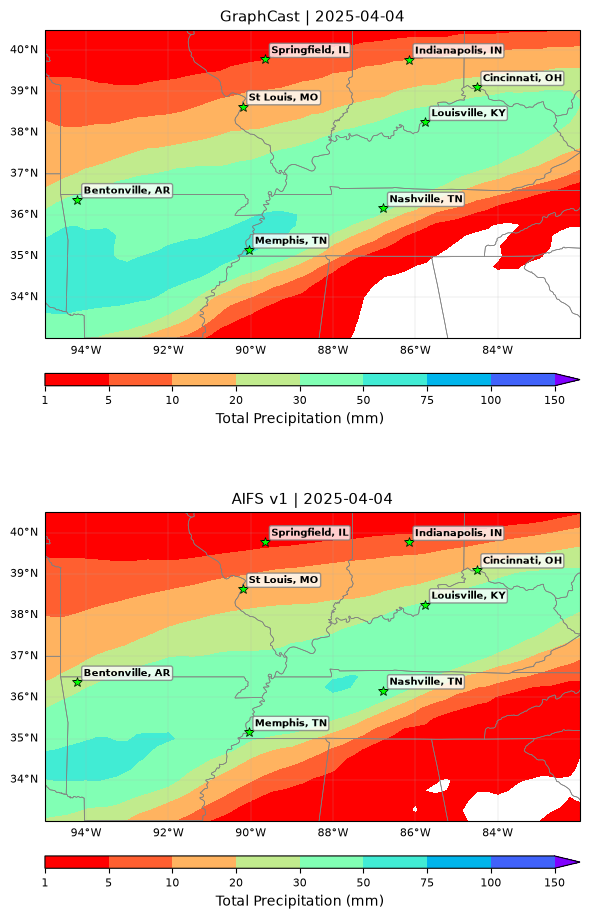


=== 2025-04-04 — daily precipitation (mm) at cities ===
                  GraphCast   AIFS   ERA5
City                                     
Springfield, IL        4.90   4.15  15.45
Indianapolis, IN       9.90   6.70  11.62
Cincinnati, OH        26.81  23.50  31.05
St Louis, MO          11.55  12.34  13.01
Louisville, KY        37.24  31.47  40.94
Bentonville, AR       34.92  27.07  31.59
Nashville, TN         35.12  40.51   1.10
Memphis, TN           53.81  37.33  11.77
Saved: tn_model_compare_outputs/model_comparison_2025-04-04.csv
Saved: tn_model_compare_outputs/model_compare_2025-04-05.png


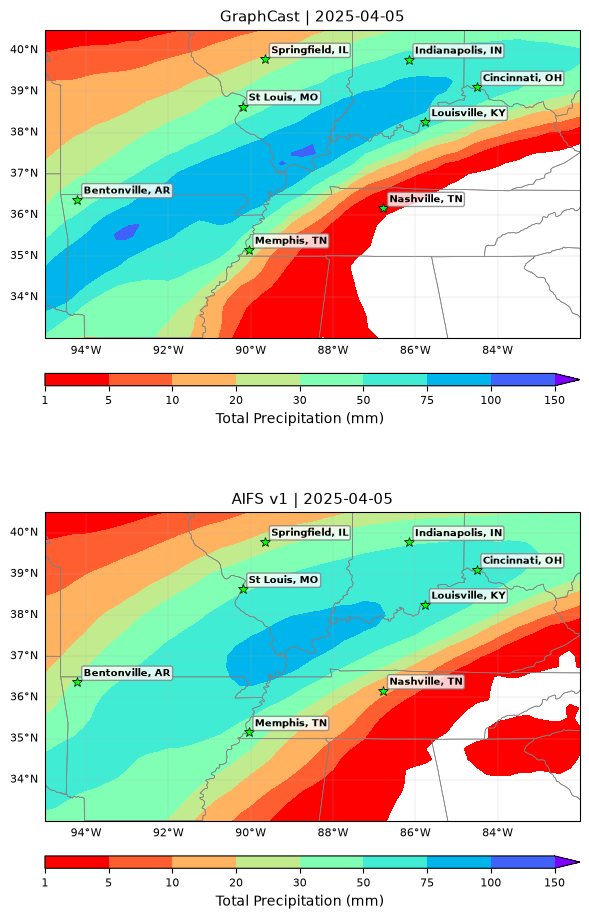


=== 2025-04-05 — daily precipitation (mm) at cities ===
                  GraphCast   AIFS   ERA5
City                                     
Springfield, IL       21.00  23.81  24.26
Indianapolis, IN      58.84  48.17  59.78
Cincinnati, OH        64.07  58.92  30.02
St Louis, MO          35.72  43.71  46.51
Louisville, KY        60.91  64.88  36.10
Bentonville, AR       42.28  33.04  26.99
Nashville, TN          1.82  13.53   3.28
Memphis, TN           28.37  40.82  72.58
Saved: tn_model_compare_outputs/model_comparison_2025-04-05.csv

=== Domain-max precipitation and location (within TN extent) ===
       model        date  max_mm    lat   lon
0  GraphCast  2025-04-04   71.60  34.50 -95.0
1       AIFS  2025-04-04   57.02  34.50 -94.5
2  GraphCast  2025-04-05  103.11  35.50 -93.0
3       AIFS  2025-04-05   88.86  37.25 -89.0
Saved: tn_model_compare_outputs/max_summary.csv


In [9]:
lon = gc_io["lon"][:]
lat = gc_io["lat"][:]

max_records = []

for date in COMPARE_DATES_2M:
    precip_gc = compute_daily_total_precip(gc_io, date, FORECAST_INIT)
    precip_ai = compute_daily_total_precip(aifs_io, date, FORECAST_INIT)
    era5_day = era5_daily.sel(day=np.datetime64(date))

    plot_model_comparison(
        precip_gc, precip_ai, date, lon, lat, EXTENT, CITIES,
        save_path=f"{OUTPUT_DIR}/model_compare_{date}.png",
    )

    rows = {}
    for city in CITIES:
        la = int(np.argmin(np.abs(lat - city["lat"])))
        lo = int(np.argmin(np.abs(lon - city["lon"])))
        rows[city["label"]] = {
            "GraphCast": round(float(precip_gc[la, lo]), 2),
            "AIFS": round(float(precip_ai[la, lo]), 2),
            "ERA5": round(float(era5_day.sel(lat=city["lat"], lon=city["lon"], method="nearest")), 2),
        }
    df = pd.DataFrame.from_dict(rows, orient="index")[["GraphCast", "AIFS", "ERA5"]]
    df.index.name = "City"
    csv_path = f"{OUTPUT_DIR}/model_comparison_{date}.csv"
    df.to_csv(csv_path)
    print(f"\n=== {date} — daily precipitation (mm) at cities ===")
    print(df)
    print(f"Saved: {csv_path}")

    for name, field in [("GraphCast", precip_gc), ("AIFS", precip_ai)]:
        mx, mlat, mlon = domain_max_location(field, lon, lat, EXTENT)
        max_records.append({
            "model": name, "date": date,
            "max_mm": round(mx, 2), "lat": round(mlat, 3), "lon": round(mlon, 3),
        })

max_df = pd.DataFrame(max_records)
max_csv = f"{OUTPUT_DIR}/max_summary.csv"
max_df.to_csv(max_csv, index=False)
print("\n=== Domain-max precipitation and location (within TN extent) ===")
print(max_df)
print(f"Saved: {max_csv}")

**How to read this.** In each figure GraphCast is on top and AIFS v1 below, on the same colour scale, so differences in colour are differences in forecast rain. The city table gives each model's daily total (mm) at the grid cell nearest each city and the ERA5 daily total at the nearest ERA5 grid cell; ERA5 is itself model-derived and smooths local extremes, so treat it as a reference, not a gauge reading. The last table lists each model's largest daily total inside the map extent and where it fell.

## 9 · Nashville time series

A single flooded city shows how the two models' daily totals differ over the whole comparison window.

Saved: tn_model_compare_outputs/nashville_precip.png


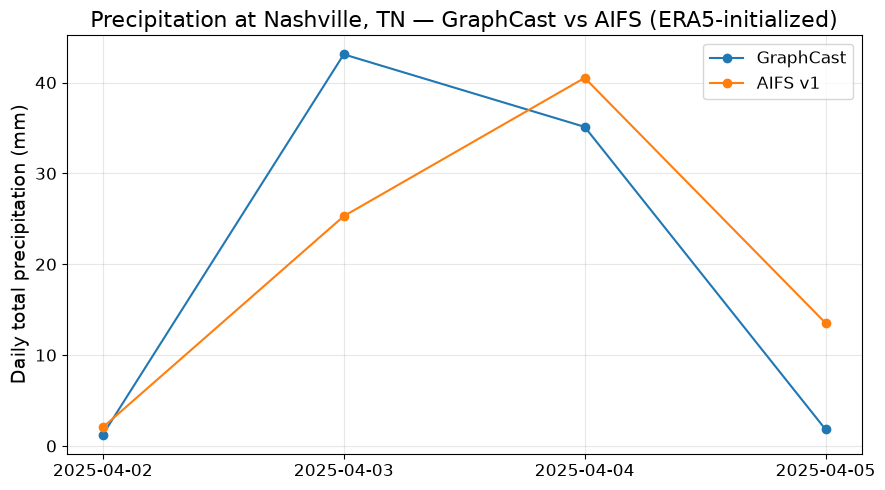

In [10]:
lat_idx = int(np.argmin(np.abs(gc_io["lat"][:] - POI_LAT)))
lon_idx = int(np.argmin(np.abs(gc_io["lon"][:] - POI_LON)))

vals_gc = [compute_daily_total_precip(gc_io, d, FORECAST_INIT)[lat_idx, lon_idx] for d in COMPARE_DATES]
vals_ai = [compute_daily_total_precip(aifs_io, d, FORECAST_INIT)[lat_idx, lon_idx] for d in COMPARE_DATES]

plt.close("all")
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(COMPARE_DATES, vals_gc, marker="o", label="GraphCast")
ax.plot(COMPARE_DATES, vals_ai, marker="o", label="AIFS v1")
ax.set_ylabel("Daily total precipitation (mm)", fontsize=14)
ax.set_title(f"Precipitation at {POI_LABEL} — GraphCast vs AIFS (ERA5-initialized)", fontsize=16)
ax.tick_params(axis="both", labelsize=12)
ax.legend(fontsize=12)
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/nashville_precip.png", dpi=150, bbox_inches="tight")
print("Saved:", f"{OUTPUT_DIR}/nashville_precip.png")
plt.show()

**How to read this.** Each line is one model's daily total (mm) at the grid cell nearest Nashville (the star labelled Nashville, TN on the section 8 maps) for April 2–5, both from the same 1 April ERA5 start. Where the lines diverge the models disagree on the point forecast; a single grid cell is noisy, so read this together with the maps and the ERA5 scores.

## Summary

- **ERA5 skill tables (section 6):** over the Tennessee Valley box, which model is closer to ERA5 in amount (Bias, RMSE, MAE) and in pattern (Pattern corr), and does the answer change from day to day? ERA5 precipitation is itself model-derived.
- **Daily maps (section 7):** where does each model put the heavy rain on 4 and 5 April?
- **Side-by-side figures, city table and domain maximum (section 8):** how do the two models differ on the same day, how do their city values compare with ERA5, and how intense and where is each model's peak?
- **Nashville time series (section 9):** how do the two models' daily totals at one flooded city compare over April 2–5?

The scores are saved to `docs/results/tennessee_valley_flood_model_comparison_metrics.csv` (mean over April 2–5) and `docs/results/tennessee_valley_flood_model_comparison_daily.csv` (per day); the figures and the per-date city tables are in `tn_model_compare_outputs/`.